<a href="https://colab.research.google.com/github/Kaihan7/Python-ML-ES/blob/main/L/L_2/l_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import math
import pickle

# Import data
with open('data.pkl', 'rb') as inp:
    data = pickle.load(inp)

x_train, y_train, x_test, y_test, x_validate, y_validate = data.values()


# Design the model

In [25]:
# Create the model
model_1 = keras.Sequential()

# Add input layer
model_1.add(keras.layers.Input(shape=(1,)))

# Add dense layer
model_1.add(keras.layers.Dense(8, activation='relu'))

# Add output layer
model_1.add(keras.layers.Dense(1))

# Compile the model
model_1.compile(optimizer='adam', loss='mse', metrics=['mae'])

model_1.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 8)              │            16 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25 (100.00 B)

 Trainable params: 25 (100.00 B)

 Non-trainable params: 0 (0.00 B)

# Train the model

In [26]:
# Train the model
history_1 = model_1.fit(
    x_train, y_train,
    epochs=500,
    batch_size=64,
    validation_data=(x_validate, y_validate),
    verbose=1
)

Epoch 1/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.6331 - mae: 0.6511 - val_loss: 0.6077 - val_mae: 0.6382
Epoch 2/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.5665 - mae: 0.6109 - val_loss: 0.5501 - val_mae: 0.6084
Epoch 3/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.5120 - mae: 0.5813 - val_loss: 0.5052 - val_mae: 0.5872
Epoch 4/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.4691 - mae: 0.5597 - val_loss: 0.4703 - val_mae: 0.5717
Epoch 5/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.4376 - mae: 0.5470 - val_loss: 0.4438 - val_mae: 0.5601
Epoch 6/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.4137 - mae: 0.5378 - val_loss: 0.4248 - val_mae: 0.5509
Epoch 7/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3964 - mae: 0.5316 - val_loss: 0.4110 - val_mae: 0.5449
Epoch 8/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3839 - mae: 0.5271 - val_loss: 0.4011 - val_mae: 0.5408
Epoch 9/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3

# Plotting training metrics

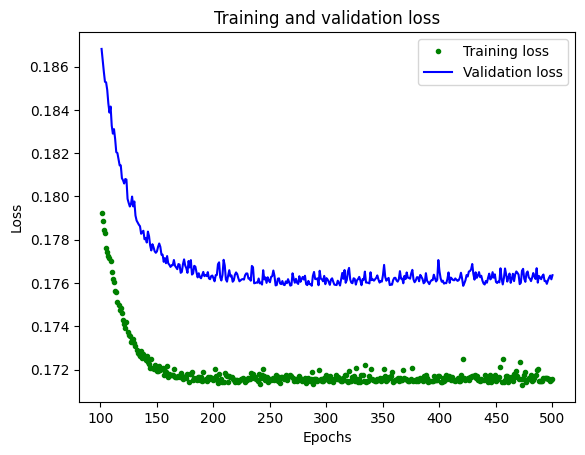

In [35]:
# Get the loss and val_loss values from history_1
loss = history_1.history['loss']
val_loss = history_1.history['val_loss']

# Define the amount of epochs
epochs = range(1, len(loss) + 1)

# Skip so the data is easier to read
SKIP = 100

# Plot the loss and val_loss
plt.plot(epochs[SKIP:], loss[SKIP:], 'g.', label='Training loss')
plt.plot(epochs[SKIP:], val_loss[SKIP:], 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

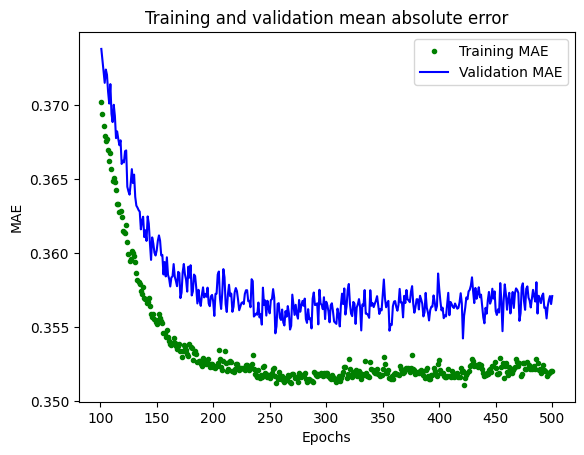

In [28]:
# Get the mae and val_mae from history_1
mae = history_1.history['mae']
val_mae = history_1.history['val_mae']

# Plot the mae and val_mae
plt.plot(epochs[SKIP:], mae[SKIP:], 'g.', label='Training MAE')
plt.plot(epochs[SKIP:], val_mae[SKIP:], 'b', label='Validation MAE')
plt.title('Training and validation mean absolute error')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend()
plt.show()

# Plot predicted value against expected values

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


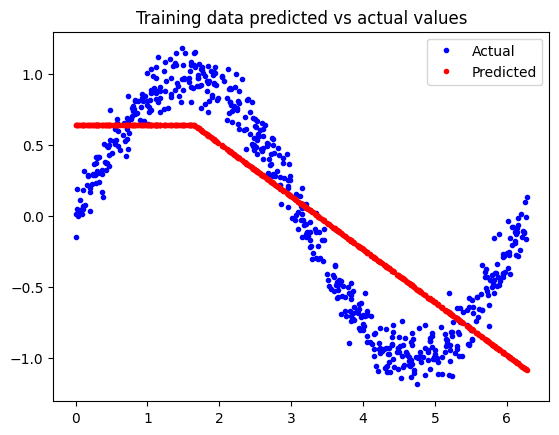

In [29]:
# Run inference on all x values from the training data. This returns an array of predictions.
predictions = model_1.predict(x_train)

# Plot the expected data along side the predicted data.
plt.clf()
plt.title('Training data predicted vs actual values')
plt.plot(x_train, y_train, 'b.', label='Actual')
plt.plot(x_train, predictions, 'r.', label='Predicted')
plt.legend()
plt.show()

# Improve the model

In [30]:
# Create the model
model_improved = keras.Sequential()

# Define the input layer
model_improved.add(keras.layers.Input(shape=(1,)))

# Increase the first layer to 16 neurons
model_improved.add(keras.layers.Dense(16, activation='relu'))

# Add a new layer
model_improved.add(keras.layers.Dense(16, activation='relu'))

# Output layer
model_improved.add(keras.layers.Dense(1))

# Compile the model
model_improved.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Summary
model_improved.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
# Train the model
history_improved = model_improved.fit(
    x_train, y_train,
    epochs=500,
    batch_size=64,
    validation_data=(x_validate, y_validate),
    verbose=1
)

Epoch 1/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.4854 - mae: 0.6217 - val_loss: 0.4819 - val_mae: 0.6154
Epoch 2/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.4368 - mae: 0.5815 - val_loss: 0.4459 - val_mae: 0.5862
Epoch 3/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.4091 - mae: 0.5571 - val_loss: 0.4237 - val_mae: 0.5662
Epoch 4/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3901 - mae: 0.5412 - val_loss: 0.4052 - val_mae: 0.5527
Epoch 5/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3735 - mae: 0.5303 - val_loss: 0.3878 - val_mae: 0.5402
Epoch 6/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3572 - mae: 0.5193 - val_loss: 0.3702 - val_mae: 0.5276
Epoch 7/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3397 - mae: 0.5068 - val_loss: 0.3483 - val_mae: 0.5098
Epoch 8/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3146 - mae: 0.4887 - val_loss: 0.3149 - val_mae: 0.4859
Epoch 9/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.

# Plot improved metrics

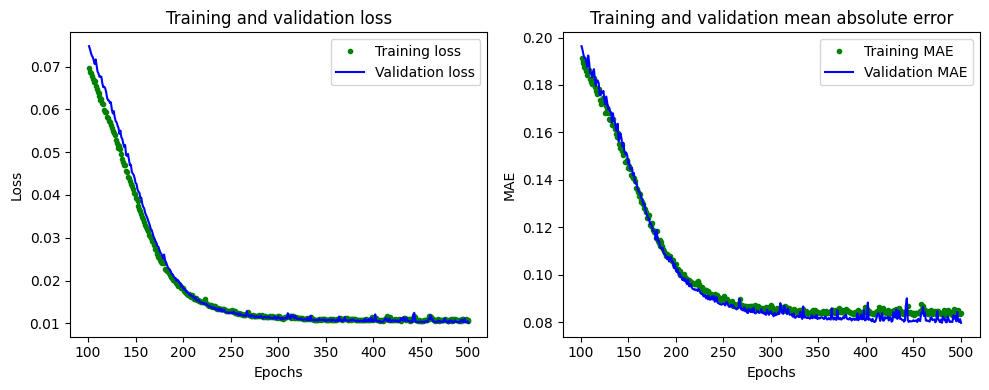

In [32]:
# Get loss and val_loss from history_improved
train_loss = history_improved.history['loss']
val_loss = history_improved.history['val_loss']

# Define the amount of epochs
epochs = range(1, len(train_loss) + 1)

SKIP = 100

# Define subplots to plot loss and mae next to eachother
plt.figure(figsize=(10,4))
plt.subplot(1, 2, 1)

# Plot the loss
plt.plot(epochs[SKIP:], train_loss[SKIP:], 'g.', label='Training loss')
plt.plot(epochs[SKIP:], val_loss[SKIP:], 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Switch subplot
plt.subplot(1, 2, 2)

# Get mae and val_mae from history_improved
train_mae = history_improved.history['mae']
val_mae = history_improved.history['val_mae']

# Plot mae and val_mae
plt.plot(epochs[SKIP:], train_mae[SKIP:], 'g.', label='Training MAE')
plt.plot(epochs[SKIP:], val_mae[SKIP:], 'b', label='Validation MAE')
plt.title('Training and validation mean absolute error')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend()

plt.tight_layout()
plt.show()

# Plot predicted values against expected values again

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0083 - mae: 0.0702 
Test Loss: 0.0083, Test MAE: 0.0702
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


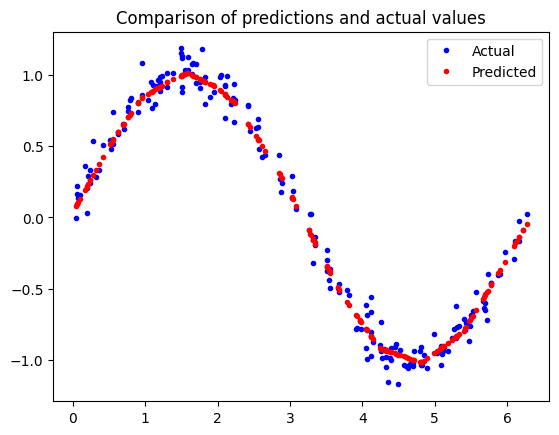

In [33]:
# Calculate loss and MAE on our test data to see how far the predictions deviate from the actual values
test_loss, test_mae = model_improved.evaluate(x_test, y_test)
print(f"Test Loss: {test_loss:.4f}, Test MAE: {test_mae:.4f}")

# Make predictions on our test dataset
predictions = model_improved.predict(x_test)

# Plot the predictions alongside the actual values
plt.clf()
plt.title('Comparison of predictions and actual values')
plt.plot(x_test, y_test, 'b.', label='Actual')
plt.plot(x_test, predictions, 'r.', label='Predicted')
plt.legend()
plt.show()

# Save model for future use

In [ ]:
model_improved.save('./model.keras')